# Clasificación de enfermedades en hojas de tomate: CNN vs. MLP

**Evaluación Parcial N.° 2 — TLY1102**

## a. Introducción y variante del problema

El objetivo es clasificar imágenes de hojas de tomate en cuatro categorías: `Tomato___Bacterial_spot`, `Tomato___Late_blight`, `Tomato___Leaf_Mold` y `Tomato___healthy`. Se conserva la variante del trabajo anterior: 500 imágenes por clase, 2.000 imágenes en total. Se implementa una CNN y se compara con un MLP usando la misma partición estratificada de entrenamiento, validación y prueba.

La variante reducida de cuatro clases facilita una comparación reproducible dentro del tiempo y recursos disponibles. El MLP procesa cada imagen aplanada y pierde la vecindad espacial; la CNN aplica filtros locales y pooling para aprender patrones espaciales jerárquicos. La comparación experimental permite medir el efecto de esa diferencia en el mismo problema.

## 1. Importación de librerías y configuración reproducible

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import display
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
from tensorflow.keras.utils import load_img, img_to_array

SEED = 2026
IMG_SIZE_CNN = (128, 128)
IMG_SIZE_MLP = (64, 64)
BATCH_SIZE = 32
EPOCHS_CNN = 20
EPOCHS_MLP = 40

tf.keras.utils.set_random_seed(SEED)

# Resolver las rutas tanto al ejecutar desde la raíz como desde notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
IMAGES_DIR = PROJECT_ROOT / "images"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "Tomato___Bacterial_spot",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___healthy",
]
print("TensorFlow:", tf.__version__)
print("Directorio del proyecto:", PROJECT_ROOT)

TensorFlow: 2.21.0
Directorio del proyecto: e:\Proyectos\PlantVillageTomato-main\PlantVillageTomato-main


## 2. Comprensión y análisis exploratorio de los datos (EDA)

Contamos imágenes por clase, verificamos que se puedan abrir y observamos ejemplos. La variante está balanceada por diseño; el chequeo de archivos permite detectar datos ilegibles antes de entrenar.

,Clase,Imágenes válidas
0,Tomato___Bacterial_spot,500
1,Tomato___Late_blight,500
2,Tomato___Leaf_Mold,500
3,Tomato___healthy,500


Total de imágenes válidas: 2000
Archivos ilegibles descartados: 0
Resoluciones originales más frecuentes: {(256, 256): 2000}


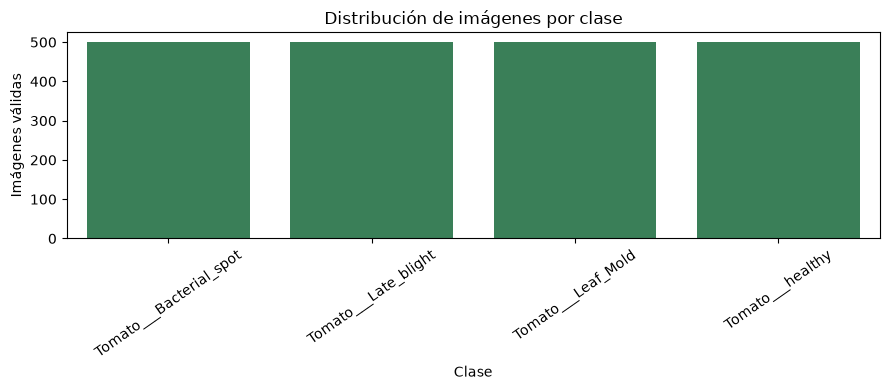

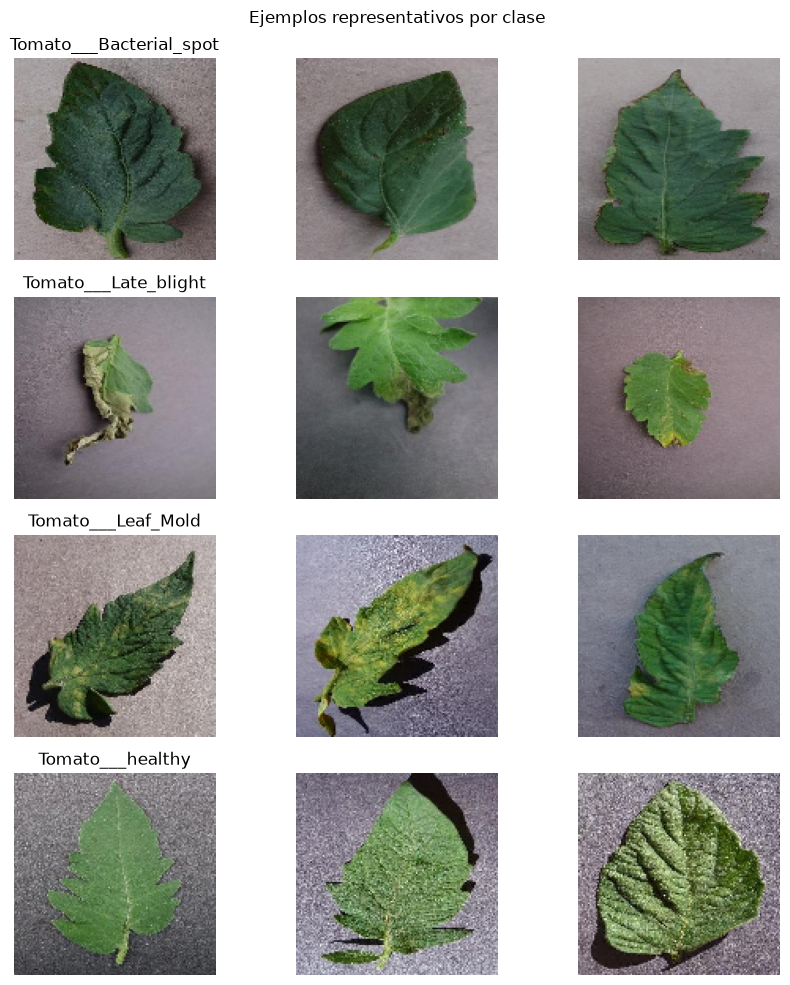

In [2]:
image_paths = []
image_labels = []
invalid_files = []
original_sizes = []

for class_index, class_name in enumerate(CLASS_NAMES):
    class_dir = DATA_DIR / class_name
    if not class_dir.is_dir():
        raise FileNotFoundError(f"No se encontró la carpeta de la clase: {class_dir}")

    class_files = sorted(
        path for path in class_dir.iterdir()
        if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    for path in class_files:
        try:
            with Image.open(path) as image:
                original_sizes.append(image.size)
                image.verify()
        except (OSError, UnidentifiedImageError):
            invalid_files.append(path)
            continue
        image_paths.append(str(path))
        image_labels.append(class_index)

if not image_paths:
    raise ValueError(f"No se encontraron imágenes válidas en {DATA_DIR}.")

class_counts = pd.Series(image_labels).value_counts().reindex(
    range(len(CLASS_NAMES)), fill_value=0
)
eda_table = pd.DataFrame({"Clase": CLASS_NAMES, "Imágenes válidas": class_counts.values})
display(eda_table)
print(f"Total de imágenes válidas: {len(image_paths)}")
print(f"Archivos ilegibles descartados: {len(invalid_files)}")
print("Resoluciones originales más frecuentes:", pd.Series(original_sizes).value_counts().head(5).to_dict())

fig, axis = plt.subplots(figsize=(9, 4))
sns.barplot(data=eda_table, x="Clase", y="Imágenes válidas", ax=axis, color="seagreen")
axis.set_title("Distribución de imágenes por clase")
axis.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(9, 10))
for row, class_name in enumerate(CLASS_NAMES):
    class_samples = [
        path for path, label in zip(image_paths, image_labels) if label == row
    ][:3]
    for column, path in enumerate(class_samples):
        axes[row, column].imshow(load_img(path, target_size=IMG_SIZE_CNN))
        axes[row, column].set_title(class_name if column == 0 else "")
        axes[row, column].axis("off")
    for column in range(len(class_samples), 3):
        axes[row, column].axis("off")
fig.suptitle("Ejemplos representativos por clase")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "eda_muestras_clases.png", bbox_inches="tight", dpi=140)
plt.show()

## 3. Preparación de datos y partición

La CNN recibe tensores RGB de 128×128×3; el MLP recibe las mismas imágenes redimensionadas a 64×64×3 y aplanadas en 12.288 características. Primero se separan rutas y etiquetas de forma estratificada (70 % entrenamiento, 15 % validación y 15 % prueba); ambos modelos utilizan exactamente los mismos ejemplos en cada partición. La prueba se reserva para la evaluación final.

In [3]:
paths = np.asarray(image_paths)
labels = np.asarray(image_labels, dtype=np.int32)

train_paths, temp_paths, y_train, y_temp = train_test_split(
    paths, labels, test_size=0.30, random_state=SEED, stratify=labels
)
val_paths, test_paths, y_val, y_test = train_test_split(
    temp_paths, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"Entrenamiento: {len(train_paths)} | Validación: {len(val_paths)} | Prueba: {len(test_paths)}")
print("Distribución en prueba:", dict(zip(CLASS_NAMES, np.bincount(y_test, minlength=len(CLASS_NAMES)))))

AUTOTUNE = tf.data.AUTOTUNE

def decode_and_resize(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE_CNN, antialias=True)
    return image, tf.cast(label, tf.int32)

def make_dataset(file_paths, file_labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((file_paths, file_labels))
    if training:
        dataset = dataset.shuffle(
            len(file_paths), seed=SEED, reshuffle_each_iteration=True
        )
    dataset = dataset.map(decode_and_resize, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_paths, y_train, training=True)
val_ds = make_dataset(val_paths, y_val)
test_ds = make_dataset(test_paths, y_test)

Entrenamiento: 1400 | Validación: 300 | Prueba: 300
Distribución en prueba: {'Tomato___Bacterial_spot': np.int64(75), 'Tomato___Late_blight': np.int64(75), 'Tomato___Leaf_Mold': np.int64(75), 'Tomato___healthy': np.int64(75)}


## 4. Diseño e implementación de la CNN

En una convolución, un filtro aprendible recorre la imagen según el `stride`; en cada posición calcula productos entre sus pesos y la región local, suma esos valores y un sesgo, y aplica una activación. Con `padding="same"` se conserva el tamaño espacial antes del pooling. Los pesos se ajustan mediante retropropagación durante el entrenamiento. `MaxPooling2D` resume regiones locales tomando su valor máximo y reduce alto/ancho, conservando las respuestas más fuertes. A diferencia del MLP, la CNN comparte filtros entre posiciones y mantiene la estructura espacial.

Tres bloques convolucionales (32, 64 y 128 filtros de 3×3) extraen patrones cada vez más complejos; `MaxPooling2D` reduce las dimensiones espaciales y el costo computacional. `BatchNormalization` estabiliza el entrenamiento. `GlobalAveragePooling2D` y una capa densa de 128 unidades realizan la clasificación final; `Dropout(0.4)` ayuda a reducir el sobreajuste. La salida `softmax` tiene cuatro unidades, una por clase.

La rotación aleatoria de ±14,4°, el zoom de ±10 % y el volteo horizontal se aplican solo durante entrenamiento. Los píxeles se reescalan a [0, 1] dentro del modelo.

In [4]:
data_augmentation = models.Sequential(
    [
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.04, seed=SEED + 1),
        layers.RandomZoom(0.10, seed=SEED + 2),
    ],
    name="aumento_datos",
)

cnn_model = models.Sequential(
    [
        layers.Input(shape=(*IMG_SIZE_CNN, 3)),
        layers.Rescaling(1.0 / 255),
        data_augmentation,
        layers.Conv2D(32, 3, padding="same", use_bias=False, name="conv1"),
        layers.BatchNormalization(momentum=0.9, name="bn1"),
        layers.Activation("relu", name="relu1"),
        layers.MaxPooling2D(name="pool1"),
        layers.Conv2D(64, 3, padding="same", use_bias=False, name="conv2"),
        layers.BatchNormalization(momentum=0.9, name="bn2"),
        layers.Activation("relu", name="relu2"),
        layers.MaxPooling2D(name="pool2"),
        layers.Conv2D(128, 3, padding="same", use_bias=False, name="conv3"),
        layers.BatchNormalization(momentum=0.9, name="bn3"),
        layers.Activation("relu", name="relu3"),
        layers.MaxPooling2D(name="pool3"),
        layers.GlobalAveragePooling2D(name="global_average_pooling"),
        layers.Dense(128, activation="relu", name="dense_features"),
        layers.Dropout(0.4, seed=SEED, name="dropout"),
        layers.Dense(len(CLASS_NAMES), activation="softmax", name="class_output"),
    ],
    name="cnn_tomate",
)

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
cnn_model.summary()

Model: "cnn_tomate"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_datos (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 128, 128, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 64, 64, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 32, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_output (Dense)            │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,948 (433.39 KB)

 Trainable params: 110,500 (431.64 KB)

 Non-trainable params: 448 (1.75 KB)

## 5. Entrenamiento de la CNN

`EarlyStopping` restaura los pesos de la época con menor pérdida de validación. `ReduceLROnPlateau` reduce la tasa de aprendizaje si la validación deja de mejorar. Se registra el tiempo real de entrenamiento.

In [5]:
cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    ),
]

cnn_start = time.perf_counter()
cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN,
    callbacks=cnn_callbacks,
    verbose=2,
)
cnn_training_seconds = time.perf_counter() - cnn_start
cnn_model.save(MODELS_DIR / "modelo_cnn_plantdisease.keras")
print(f"Tiempo de entrenamiento CNN: {cnn_training_seconds:.1f} s")

Epoch 1/20


c:\Users\srrod\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


44/44 - 15s - 335ms/step - accuracy: 0.6021 - loss: 0.9776 - val_accuracy: 0.5400 - val_loss: 0.9887 - learning_rate: 3.0000e-04
Epoch 2/20
44/44 - 13s - 290ms/step - accuracy: 0.8307 - loss: 0.5375 - val_accuracy: 0.5067 - val_loss: 1.3213 - learning_rate: 3.0000e-04
Epoch 3/20
44/44 - 12s - 282ms/step - accuracy: 0.8779 - loss: 0.4146 - val_accuracy: 0.6867 - val_loss: 0.7981 - learning_rate: 3.0000e-04
Epoch 4/20
44/44 - 12s - 282ms/step - accuracy: 0.8907 - loss: 0.3534 - val_accuracy: 0.6600 - val_loss: 0.8176 - learning_rate: 3.0000e-04
Epoch 5/20
44/44 - 13s - 286ms/step - accuracy: 0.9150 - loss: 0.2888 - val_accuracy: 0.8133 - val_loss: 0.4700 - learning_rate: 3.0000e-04
Epoch 6/20
44/44 - 13s - 287ms/step - accuracy: 0.9329 - loss: 0.2412 - val_accuracy: 0.5633 - val_loss: 1.4527 - learning_rate: 3.0000e-04
Epoch 7/20
44/44 - 13s - 287ms/step - accuracy: 0.9157 - loss: 0.2653 - val_accuracy: 0.6033 - val_loss: 1.2015 - learning_rate: 3.0000e-04
Epoch 8/20
44/44 - 12s - 280ms/

## 6. Entrenamiento de una línea base MLP comparable

Para que la comparación sea experimentalmente justa, este notebook vuelve a entrenar la arquitectura MLP del trabajo anterior (128 y 64 neuronas, `Dropout(0.2)`, Adam con tasa 0,0005) con la misma partición de archivos. A diferencia de la CNN, cada imagen 64×64×3 se aplana en un vector. El costo de memoria del MLP es mayor, pero se mantiene la misma variante y etiquetas.

In [6]:
def load_flat_images(file_paths):
    image_vectors = []
    for file_path in file_paths:
        image = load_img(file_path, target_size=IMG_SIZE_MLP, color_mode="rgb")
        vector = img_to_array(image).astype("float32") / 255.0
        image_vectors.append(vector.reshape(-1))
    return np.asarray(image_vectors, dtype=np.float32)

X_train_mlp = load_flat_images(train_paths)
X_val_mlp = load_flat_images(val_paths)
X_test_mlp = load_flat_images(test_paths)

tf.keras.utils.set_random_seed(SEED)
mlp_model = models.Sequential(
    [
        layers.Input(shape=(X_train_mlp.shape[1],)),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(len(CLASS_NAMES), activation="softmax"),
    ],
    name="mlp_tomate",
)
mlp_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
mlp_model.summary()

mlp_start = time.perf_counter()
mlp_history = mlp_model.fit(
    X_train_mlp,
    y_train,
    validation_data=(X_val_mlp, y_val),
    epochs=EPOCHS_MLP,
    batch_size=BATCH_SIZE,
    verbose=2,
)
mlp_training_seconds = time.perf_counter() - mlp_start
mlp_model.save(MODELS_DIR / "modelo_mlp_comparacion.keras")
print(f"Tiempo de entrenamiento MLP: {mlp_training_seconds:.1f} s")

Model: "mlp_tomate"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,581,508 (6.03 MB)

 Trainable params: 1,581,508 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
44/44 - 1s - 22ms/step - accuracy: 0.2686 - loss: 1.9021 - val_accuracy: 0.3533 - val_loss: 1.3121
Epoch 2/40
44/44 - 0s - 8ms/step - accuracy: 0.3779 - loss: 1.3091 - val_accuracy: 0.4900 - val_loss: 1.2662
Epoch 3/40
44/44 - 0s - 8ms/step - accuracy: 0.4436 - loss: 1.2290 - val_accuracy: 0.6133 - val_loss: 1.1833
Epoch 4/40
44/44 - 0s - 8ms/step - accuracy: 0.4886 - loss: 1.1641 - val_accuracy: 0.6000 - val_loss: 1.1430
Epoch 5/40
44/44 - 0s - 8ms/step - accuracy: 0.5221 - loss: 1.1005 - val_accuracy: 0.5867 - val_loss: 1.0307
Epoch 6/40
44/44 - 0s - 8ms/step - accuracy: 0.5771 - loss: 1.0065 - val_accuracy: 0.6500 - val_loss: 0.9900
Epoch 7/40
44/44 - 0s - 8ms/step - accuracy: 0.5693 - loss: 1.0109 - val_accuracy: 0.6167 - val_loss: 0.9279
Epoch 8/40
44/44 - 0s - 8ms/step - accuracy: 0.6071 - loss: 0.9311 - val_accuracy: 0.6567 - val_loss: 0.9052
Epoch 9/40
44/44 - 0s - 8ms/step - accuracy: 0.6057 - loss: 0.9407 - val_accuracy: 0.6433 - val_loss: 0.8907
Epoch 10/40
44/44 

## 7. Curvas de entrenamiento y validación

Las curvas permiten detectar divergencia entre entrenamiento y validación. Una pérdida de entrenamiento que siga bajando mientras la pérdida de validación sube puede indicar sobreajuste.

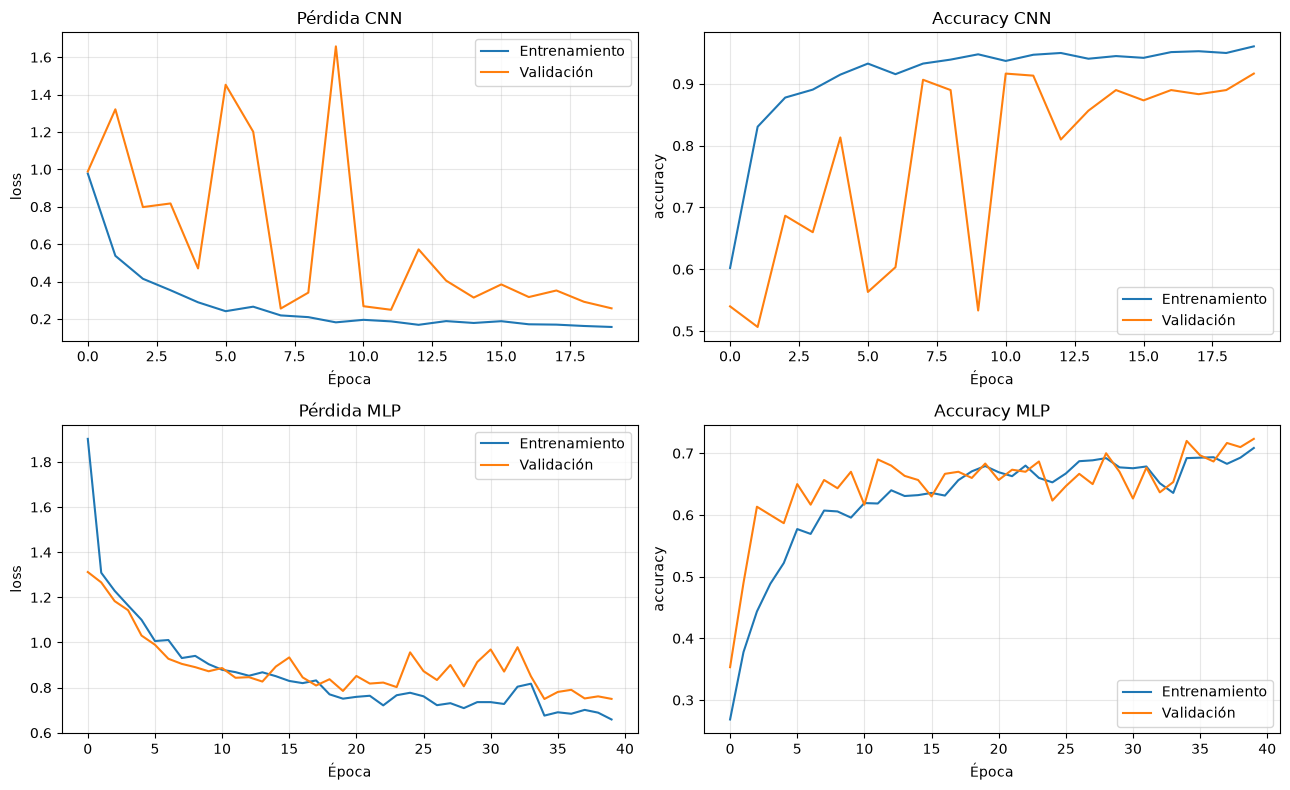

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for axis, history, metric, title in [
    (axes[0, 0], cnn_history, "loss", "Pérdida CNN"),
    (axes[0, 1], cnn_history, "accuracy", "Accuracy CNN"),
    (axes[1, 0], mlp_history, "loss", "Pérdida MLP"),
    (axes[1, 1], mlp_history, "accuracy", "Accuracy MLP"),
]:
    axis.plot(history.history[metric], label="Entrenamiento")
    axis.plot(history.history[f"val_{metric}"], label="Validación")
    axis.set_title(title)
    axis.set_xlabel("Época")
    axis.set_ylabel(metric)
    axis.legend()
    axis.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(IMAGES_DIR / "curvas_entrenamiento_comparacion.png", bbox_inches="tight", dpi=140)
plt.show()

## 8. Evaluación en el conjunto de prueba

El conjunto de prueba no se utiliza para ajustar los modelos. Reportamos accuracy, precision, recall y F1 macro, además del reporte por clase y las matrices de confusión.

,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,Parámetros,Entrenamiento (s),Inferencia (ms/imagen)
0,CNN,0.8933,0.9021,0.8933,0.8931,110948,251.5500,2.0498
1,MLP,0.7200,0.7157,0.7200,0.7126,1581508,14.0098,0.3100


=== REPORTE CNN ===
                         precision    recall  f1-score   support

Tomato___Bacterial_spot       0.96      0.93      0.95        75
   Tomato___Late_blight       0.90      0.83      0.86        75
     Tomato___Leaf_Mold       0.95      0.81      0.88        75
       Tomato___healthy       0.80      1.00      0.89        75

               accuracy                           0.89       300
              macro avg       0.90      0.89      0.89       300
           weighted avg       0.90      0.89      0.89       300

=== REPORTE MLP ===
                         precision    recall  f1-score   support

Tomato___Bacterial_spot       0.71      0.81      0.76        75
   Tomato___Late_blight       0.62      0.48      0.54        75
     Tomato___Leaf_Mold       0.79      0.71      0.75        75
       Tomato___healthy       0.74      0.88      0.80        75

               accuracy                           0.72       300
              macro avg       0.72      0.72 

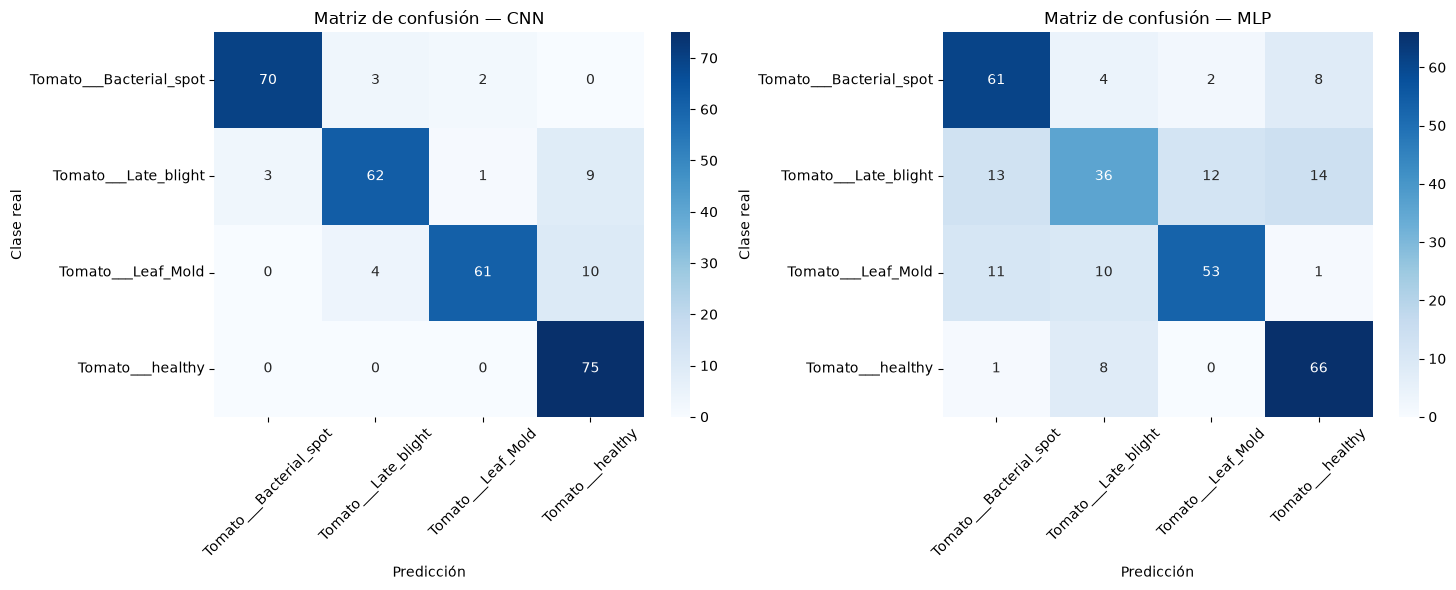

In [8]:
X_test_cnn = np.concatenate([images.numpy() for images, _ in test_ds], axis=0)
y_test_ordered = np.concatenate([targets.numpy() for _, targets in test_ds], axis=0)

cnn_start = time.perf_counter()
cnn_probabilities = cnn_model.predict(X_test_cnn, batch_size=BATCH_SIZE, verbose=0)
cnn_inference_ms = (time.perf_counter() - cnn_start) * 1000 / len(y_test_ordered)
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

mlp_start = time.perf_counter()
mlp_probabilities = mlp_model.predict(X_test_mlp, batch_size=BATCH_SIZE, verbose=0)
mlp_inference_ms = (time.perf_counter() - mlp_start) * 1000 / len(y_test)
mlp_predictions = np.argmax(mlp_probabilities, axis=1)

assert np.array_equal(y_test_ordered, y_test), "El orden de etiquetas CNN y MLP no coincide."

def summarize_metrics(y_true, y_pred, model, training_seconds, inference_ms):
    return {
        "Modelo": model,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Parámetros": cnn_model.count_params() if model == "CNN" else mlp_model.count_params(),
        "Entrenamiento (s)": training_seconds,
        "Inferencia (ms/imagen)": inference_ms,
    }

comparison = pd.DataFrame(
    [
        summarize_metrics(y_test, cnn_predictions, "CNN", cnn_training_seconds, cnn_inference_ms),
        summarize_metrics(y_test, mlp_predictions, "MLP", mlp_training_seconds, mlp_inference_ms),
    ]
)
display(comparison.round(4))
comparison.to_csv(IMAGES_DIR / "metricas_comparacion.csv", index=False)

print("=== REPORTE CNN ===")
print(classification_report(y_test, cnn_predictions, target_names=CLASS_NAMES, zero_division=0))
print("=== REPORTE MLP ===")
print(classification_report(y_test, mlp_predictions, target_names=CLASS_NAMES, zero_division=0))

metricas_por_modelo = comparison.set_index("Modelo")
diferencia_f1 = metricas_por_modelo.loc["CNN", "F1 macro"] - metricas_por_modelo.loc["MLP", "F1 macro"]
if diferencia_f1 > 0:
    print(f"La CNN supera al MLP en F1 macro por {diferencia_f1:.4f} en este conjunto de prueba.")
elif diferencia_f1 < 0:
    print(f"El MLP supera a la CNN en F1 macro por {abs(diferencia_f1):.4f} en este conjunto de prueba.")
else:
    print("CNN y MLP obtuvieron el mismo F1 macro en este conjunto de prueba.")
cnn_class_report = classification_report(
    y_test, cnn_predictions, target_names=CLASS_NAMES, output_dict=True, zero_division=0
)
clase_menor_recall = min(
    CLASS_NAMES, key=lambda class_name: cnn_class_report[class_name]["recall"]
)
print(
    f"Menor recall CNN: {clase_menor_recall} "
    f"({cnn_class_report[clase_menor_recall]['recall']:.3f}); "
    "revisar sus falsos negativos y ejemplos en las visualizaciones."
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for axis, predictions, title in zip(
    axes, [cnn_predictions, mlp_predictions], ["CNN", "MLP"]
):
    matrix = confusion_matrix(y_test, predictions, labels=range(len(CLASS_NAMES)))
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axis
    )
    axis.set_title(f"Matriz de confusión — {title}")
    axis.set_xlabel("Predicción")
    axis.set_ylabel("Clase real")
    axis.tick_params(axis="x", rotation=45)
    axis.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig(IMAGES_DIR / "matriz_confusion_comparativa.png", bbox_inches="tight", dpi=140)
plt.show()

## 9. Análisis de errores

Revisamos predicciones incorrectas de la CNN en el conjunto de prueba. La matriz de confusión y el reporte por clase ayudan a identificar las categorías más difíciles; los ejemplos deben interpretarse como evidencia cualitativa, no como una explicación causal definitiva.

Errores CNN: 32 de 300 imágenes de prueba.


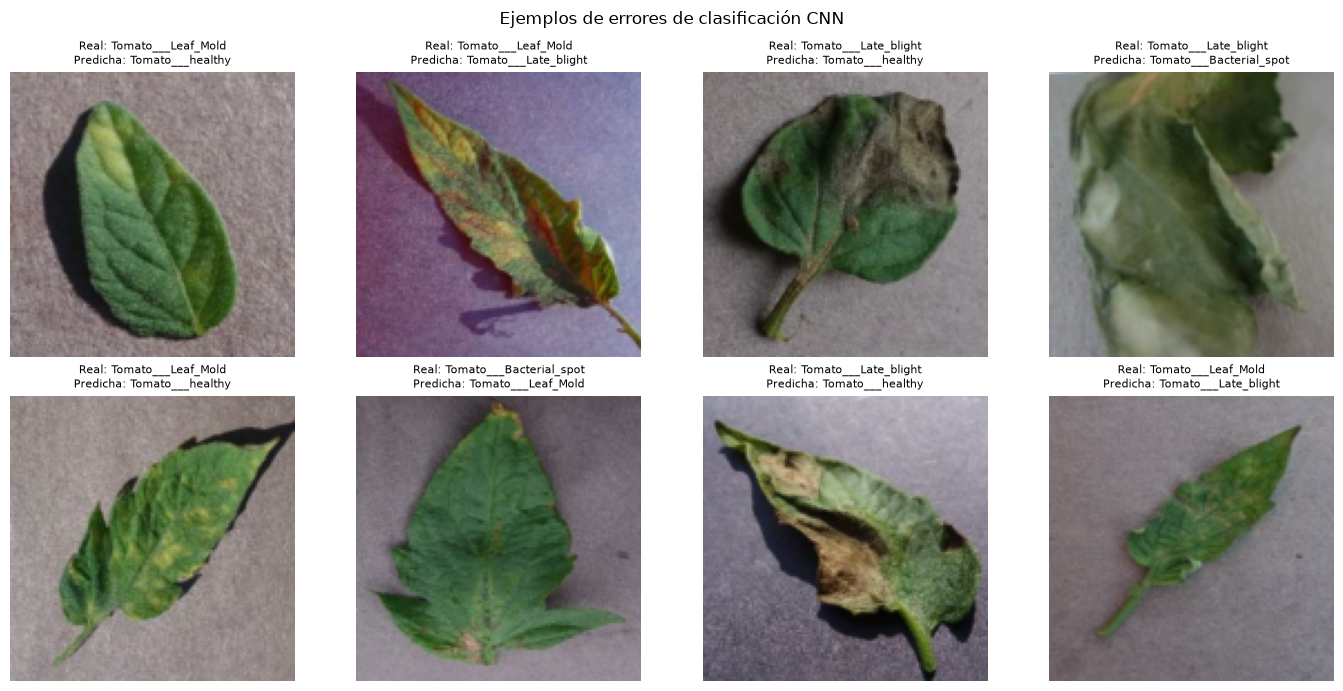

Clases con más errores CNN:


,Errores
Tomato___Leaf_Mold,14
Tomato___Late_blight,13
Tomato___Bacterial_spot,5


In [9]:
cnn_error_indices = np.flatnonzero(cnn_predictions != y_test)
print(f"Errores CNN: {len(cnn_error_indices)} de {len(y_test)} imágenes de prueba.")

if len(cnn_error_indices) == 0:
    print("No hubo errores CNN en este conjunto de prueba.")
else:
    selected_errors = cnn_error_indices[:8]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for axis, index in zip(axes.flat, selected_errors):
        axis.imshow(np.clip(X_test_cnn[index] / 255.0, 0, 1))
        axis.set_title(
            f"Real: {CLASS_NAMES[y_test[index]]}\nPredicha: {CLASS_NAMES[cnn_predictions[index]]}",
            fontsize=8,
        )
        axis.axis("off")
    for axis in list(axes.flat)[len(selected_errors):]:
        axis.axis("off")
    fig.suptitle("Ejemplos de errores de clasificación CNN")
    plt.tight_layout()
    plt.savefig(IMAGES_DIR / "ejemplos_errores_cnn.png", bbox_inches="tight", dpi=140)
    plt.show()

print("Clases con más errores CNN:")
error_counts = pd.Series(y_test[cnn_error_indices]).map(dict(enumerate(CLASS_NAMES))).value_counts()
display(error_counts.rename("Errores").to_frame())

## 10. Mapas de características y mapas de activación

Visualizamos activaciones de distintas profundidades de la CNN entrenada. Las primeras capas suelen responder a patrones locales simples; las capas posteriores combinan información espacial más amplia. Los mapas no son etiquetas ni explicaciones causales del diagnóstico. A continuación usamos Grad-CAM para resaltar regiones que influyen en la puntuación de una clase.

relu1: tensor de activación (1, 128, 128, 32)
relu2: tensor de activación (1, 64, 64, 64)
relu3: tensor de activación (1, 32, 32, 128)


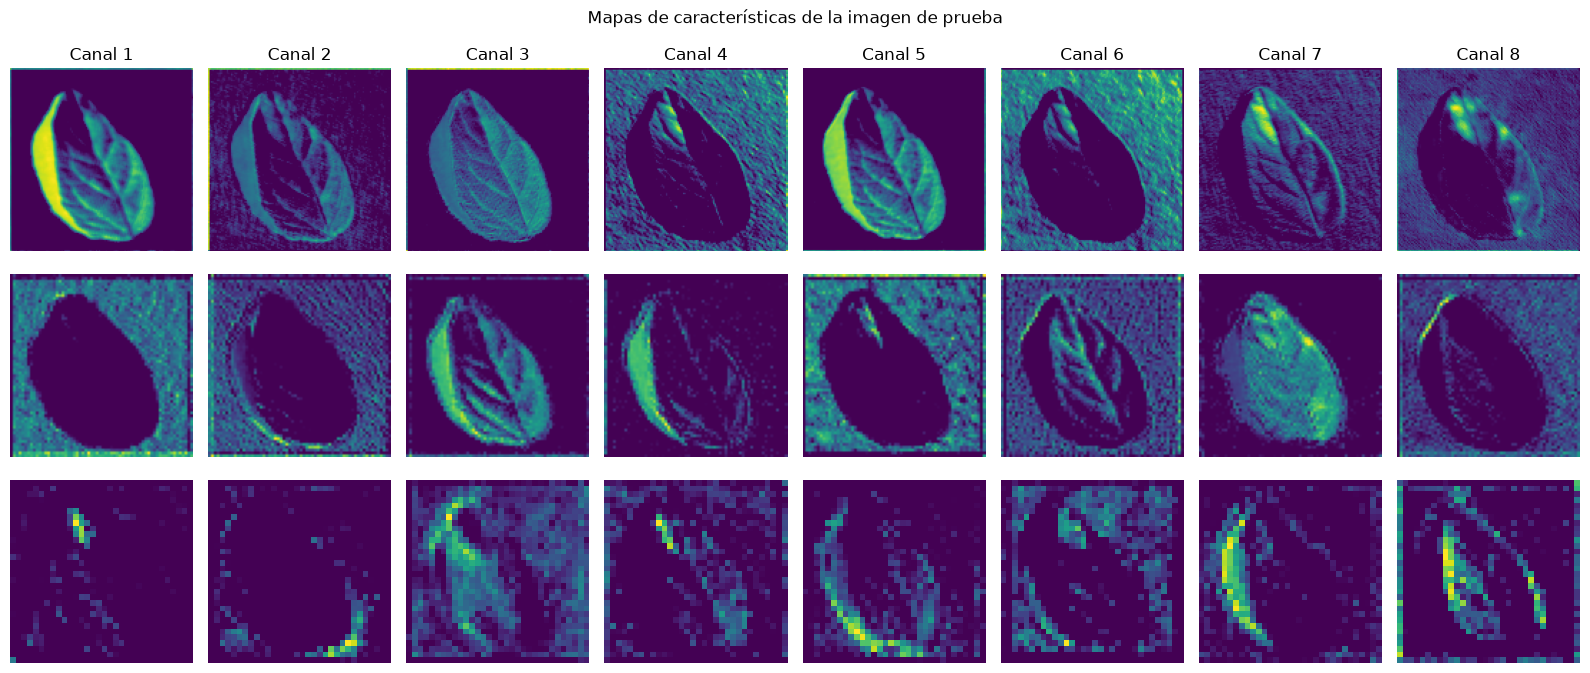

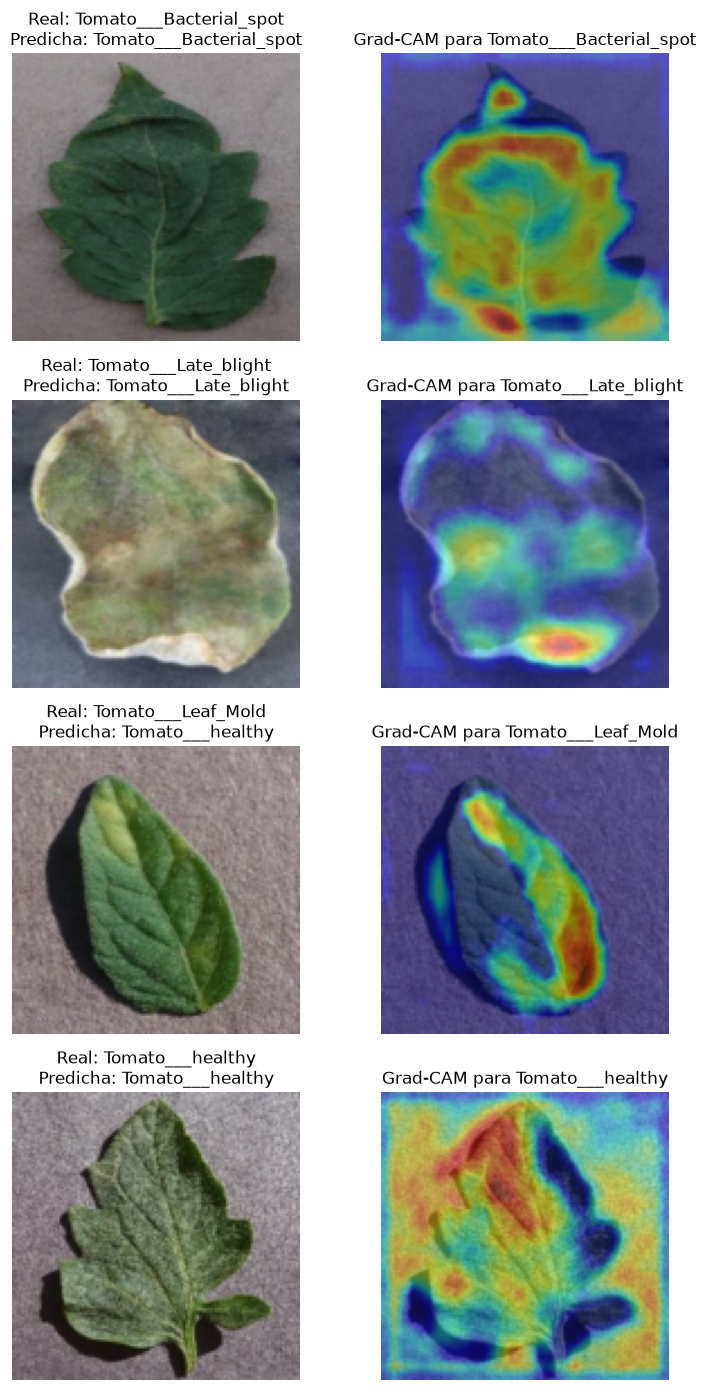

In [10]:
feature_layers = ["relu1", "relu2", "relu3"]
feature_model = models.Model(
    inputs=cnn_model.inputs,
    outputs=[cnn_model.get_layer(name).output for name in feature_layers],
)
feature_maps = feature_model.predict(X_test_cnn[:1], verbose=0)
for layer_name, layer_maps in zip(feature_layers, feature_maps):
    print(f"{layer_name}: tensor de activación {layer_maps.shape}")

fig, axes = plt.subplots(len(feature_maps), 8, figsize=(16, 7))
for row, (layer_name, layer_maps) in enumerate(zip(feature_layers, feature_maps)):
    n_maps = min(8, layer_maps.shape[-1])
    for column in range(8):
        axis = axes[row, column]
        if column < n_maps:
            axis.imshow(layer_maps[0, :, :, column], cmap="viridis")
            if row == 0:
                axis.set_title(f"Canal {column + 1}")
        axis.axis("off")
    axes[row, 0].set_ylabel(layer_name, rotation=0, labelpad=45, va="center")
fig.suptitle("Mapas de características de la imagen de prueba")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "feature_maps_cnn.png", bbox_inches="tight", dpi=140)
plt.show()

grad_model = models.Model(
    inputs=cnn_model.inputs,
    outputs=[
        cnn_model.get_layer("relu3").output,
        cnn_model.get_layer("class_output").output,
    ],
)

def grad_cam(image_batch, class_index):
    image_tensor = tf.convert_to_tensor(image_batch, dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_output, probabilities = grad_model(image_tensor, training=False)
        class_score = probabilities[:, class_index]
    gradients = tape.gradient(class_score, conv_output)
    if gradients is None:
        raise RuntimeError(
            "No se pudo calcular el gradiente de Grad-CAM. "
            "Comprueba que la salida de clase esté conectada a la capa convolucional."
        )
    channel_weights = tf.reduce_mean(gradients, axis=(1, 2))
    cam = tf.reduce_sum(conv_output * channel_weights[:, tf.newaxis, tf.newaxis, :], axis=-1)
    cam = tf.maximum(cam, 0)
    cam = cam / (tf.reduce_max(cam, axis=(1, 2), keepdims=True) + 1e-8)
    cam = tf.image.resize(cam[..., tf.newaxis], IMG_SIZE_CNN)
    return cam[0, :, :, 0].numpy()

fig, axes = plt.subplots(len(CLASS_NAMES), 2, figsize=(8, 14))
for class_index, class_name in enumerate(CLASS_NAMES):
    sample_indices = np.flatnonzero(y_test == class_index)
    if len(sample_indices) == 0:
        raise ValueError(f"No hay muestras de prueba para la clase {class_name}.")
    sample_index = sample_indices[0]
    sample = X_test_cnn[sample_index:sample_index + 1]
    heatmap = grad_cam(sample, class_index)
    axes[class_index, 0].imshow(np.clip(sample[0] / 255.0, 0, 1))
    axes[class_index, 0].set_title(
        f"Real: {class_name}\nPredicha: {CLASS_NAMES[cnn_predictions[sample_index]]}"
    )
    axes[class_index, 1].imshow(np.clip(sample[0] / 255.0, 0, 1))
    axes[class_index, 1].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[class_index, 1].set_title(f"Grad-CAM para {class_name}")
    axes[class_index, 0].axis("off")
    axes[class_index, 1].axis("off")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "gradcam_por_clase.png", bbox_inches="tight", dpi=140)
plt.show()

## 11. Interpretación y conclusiones

Usa la tabla y los gráficos producidos al ejecutar el notebook para completar esta interpretación con resultados observados; no reemplaces los valores por estimaciones.

- **Desempeño:** compara accuracy y F1 macro; consulta el reporte por clase y la matriz de confusión para identificar diferencias entre categorías.
- **Generalización:** contrasta las curvas de entrenamiento y validación. Si hay una brecha persistente, considera mayor regularización, más datos o ajustar la arquitectura.
- **CNN vs. MLP:** relaciona las métricas y parámetros con la preservación de la estructura espacial de la CNN y el aplanado del MLP. El tiempo depende del hardware; compara los tiempos medidos en la misma ejecución.
- **Limitaciones y uso responsable:** el subconjunto es pequeño y proviene de imágenes de PlantVillage; fondos y condiciones controladas pueden diferir del campo. Los resultados no garantizan desempeño en otras cámaras, cultivos o condiciones y no deben usarse solos para decidir tratamientos agrícolas.
- **Mejoras posibles:** validación externa, búsqueda de hiperparámetros, balanceo/augmentación adicional y evaluación con imágenes capturadas en terreno.

## Metodología CRISP-DM

1. **Comprensión del negocio:** detección de enfermedades foliares para apoyar la inspección temprana.
2. **Comprensión de los datos:** distribución, calidad de lectura y ejemplos por clase.
3. **Preparación de datos:** redimensionamiento, normalización, aumento de datos solo en entrenamiento y partición estratificada reproducible.
4. **Modelado:** CNN y MLP con los mismos archivos de entrenamiento y validación.
5. **Evaluación:** métricas múltiples, matrices de confusión, curvas y análisis cualitativo de errores.
6. **Despliegue:** fuera del alcance de esta evaluación; antes de un uso real se requiere validación externa y supervisión experta.